In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [2]:
# Load your raw dataset (adjust path/filename based on your Kaggle download)
# Assumes rows are samples and columns are genes (or vice versa)
df_raw = pd.read_csv("../Data/fibrosis_smoc2_rawcounts.csv")
print("Read CSV file Successfully")

#Print shapes and a preview to see what we are dealing with
print(f"Dataset Shape: {df_raw.shape}")
print(df_raw.head())

Read CSV file Successfully
Dataset Shape: (47729, 8)
           Unnamed: 0  smoc2_fibrosis1  smoc2_fibrosis4  smoc2_normal1  \
0  ENSMUSG00000102693                0                0              0   
1  ENSMUSG00000064842                0                0              0   
2  ENSMUSG00000051951               72               30              0   
3  ENSMUSG00000102851                0                0              0   
4  ENSMUSG00000103377                0                0              1   

   smoc2_normal3  smoc2_fibrosis3  smoc2_normal4  smoc2_fibrosis2  
0              0                0              0                0  
1              0                0              0                0  
2              3               36              1               51  
3              0                0              0                0  
4              0                0              0                0  


### Data Cleaning & Transposition

In [12]:
import pandas as pd
import numpy as np

In [3]:
# 1. Clean up column names and set the Ensembl Gene IDs as the index
df = df_raw.rename(columns={'Unnamed: 0': 'gene_id'})
df.set_index('gene_id', inplace=True)

In [4]:
print(df.head())

                    smoc2_fibrosis1  smoc2_fibrosis4  smoc2_normal1  \
gene_id                                                               
ENSMUSG00000102693                0                0              0   
ENSMUSG00000064842                0                0              0   
ENSMUSG00000051951               72               30              0   
ENSMUSG00000102851                0                0              0   
ENSMUSG00000103377                0                0              1   

                    smoc2_normal3  smoc2_fibrosis3  smoc2_normal4  \
gene_id                                                             
ENSMUSG00000102693              0                0              0   
ENSMUSG00000064842              0                0              0   
ENSMUSG00000051951              3               36              1   
ENSMUSG00000102851              0                0              0   
ENSMUSG00000103377              0                0              0   

                  

In [5]:
# 2. Filtering Noise: Remove genes that have 0 expression across ALL samples
# Out of 47k+ genes, thousands will be completely silent. Let's drop them.
df = df[df.sum(axis=1) > 0]
print(f"Shape after filtering zero-expression genes: {df.shape}")

Shape after filtering zero-expression genes: (29556, 7)


In [6]:
# 3. Normalization (CPM: Counts Per Million)
# Raw counts vary based on sequencing machine depth. We scale each column to its sum.
cpm_df = df.divide(df.sum(axis=0), axis=1) * 1_000_000

In [7]:
print(cpm_df.head())

                    smoc2_fibrosis1  smoc2_fibrosis4  smoc2_normal1  \
gene_id                                                               
ENSMUSG00000051951         2.602022         1.389916       0.000000   
ENSMUSG00000103377         0.000000         0.000000       0.051324   
ENSMUSG00000103147         0.036139         0.046331       0.051324   
ENSMUSG00000103161         0.000000         0.046331       0.000000   
ENSMUSG00000102331         0.325253         0.092661       0.051324   

                    smoc2_normal3  smoc2_fibrosis3  smoc2_normal4  \
gene_id                                                             
ENSMUSG00000051951       0.135988         1.472315       0.041676   
ENSMUSG00000103377       0.000000         0.000000       0.000000   
ENSMUSG00000103147       0.000000         0.040898       0.000000   
ENSMUSG00000103161       0.000000         0.000000       0.000000   
ENSMUSG00000102331       0.045329         0.286283       0.041676   

                  

In [8]:
# 4. Log Transformation (Log2(CPM + 1))
# Stabilizes variance across highly expressed and lowly expressed genes
log_df = np.log2(cpm_df + 1)

In [9]:
# 5. Transpose the Matrix for Scikit-Learn (Flipped so Rows=Samples, Columns=Genes)
df_ml = log_df.T

In [10]:
# 6. Extract Target Labels (Y) from the original column names
# Creates 1 for fibrosis, 0 for normal
y = np.array([1 if 'fibrosis' in sample else 0 for sample in df_ml.index])

In [ ]:
print(f"\nFinal ML Feature Matrix Shape (Samples, Genes): {df_ml.shape}")
print(f"Target vector labels (0 = Normal, 1 = Fibrosis): {y}")


Final ML Feature Matrix Shape (Samples, Genes): (7, 29556)
Target vector labels (0 = Normal, 1 = Fibrosis): [1 1 0 0 1 0 1]


### Exploratory Data Analysis (EDA) & Finding SMOC2
#### Because this dataset is high-dimensional (thousands of features, but only 7 rows), we can't look at individual scatter plots for every gene. Instead, we use two methods:
#### 1. Find SMOC2: Locate the exact Ensembl identifier for SMOC2 to verify how it behaves between your normal and fibrotic samples.
#### 2. PCA (Principal Component Analysis): Reduce all 29,556 dimensions down to 2 dimensions to see if the biological patterns cleanly separate the "Healthy" samples from the "Fibrosis" samples.


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

Found SMOC2 (ENSMUSG00000024037) in the dataset!


C:\Users\epics\AppData\Local\Temp\ipykernel_8196\676208105.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=y, y=df_ml[smoc2_id], palette="Set2")


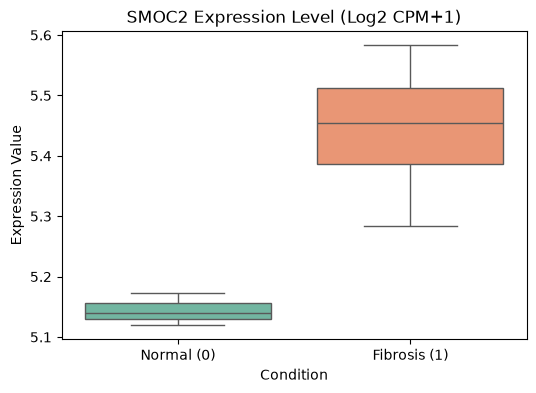

In [15]:
# --- 1. Find SMOC2 Gene Expression ---
# Let's search our column indices to find the Ensembl ID mapping to SMOC2.
# In mouse genomics, the Ensembl ID for SMOC2 is typically 'ENSMUSG00000024037'.
# Let's verify if that ID exists in our filtered matrix columns.
smoc2_id = 'ENSMUSG00000024037'

if smoc2_id in df_ml.columns:
    print(f"Found SMOC2 ({smoc2_id}) in the dataset!")
    # Plotting SMOC2 expression across conditions
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=y, y=df_ml[smoc2_id], palette="Set2")
    plt.xticks([0, 1], ['Normal (0)', 'Fibrosis (1)'])
    plt.title("SMOC2 Expression Level (Log2 CPM+1)")
    plt.ylabel("Expression Value")
    plt.xlabel("Condition")
    plt.show()
else:
    print(f"⚠️ {smoc2_id} not found under standard mouse ID. Let's look up genes manually later.")

In [16]:
# --- 2. Principal Component Analysis (PCA) ---
# Scale features before PCA (mean=0, variance=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_ml)

In [17]:
# Reduce to 2 Principal Components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

In [18]:
# Create a DataFrame for plotting the PCA results
df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_pca['Condition'] = ['Fibrosis' if val == 1 else 'Normal' for val in y]

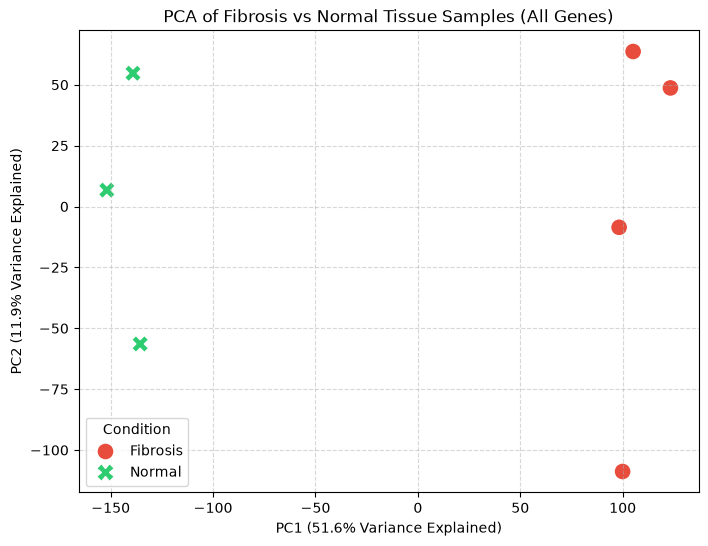

In [19]:
# Plot the PCA space
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_pca, 
    x='PC1', 
    y='PC2', 
    hue='Condition', 
    style='Condition', 
    s=150, 
    palette=['#e74c3c', '#2ecc71']
)
plt.title("PCA of Fibrosis vs Normal Tissue Samples (All Genes)")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance Explained)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance Explained)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()